# T5. 서울 생활 데이터 레이크하우스

아파트 실거래 · 음식점 상가 · 행정동 생활인구 · 따릉이 대여 — 기관도 키도 다른 2026년 6월 서울 자료 넷을 MinIO 원본 층에 올리고, Spark 로 행정동 · 자치구 키를 맞춰(코드 불일치 21곳 대응표 · 대여소 번호 · 좌표로 동 붙이기) Iceberg 테이블 여섯 개로 적재한 뒤, Trino 로 「생활인구 대비 카페 · 거래 · 대여가 많은 동네」를 교차 질의합니다. 월 1회 도는 Airflow DAG 까지 만듭니다.

- 단계: 팀 프로젝트 · 정형 · 예상 3일(팀 규모 · 혼자 진행)
- 실행 환경: 내 컴퓨터의 Docker + Jupyter(VS Code 노트북도 됩니다)
- 데이터: 서울 열린데이터광장 — 서울시 부동산 실거래가 정보(OA-21275) 계약일 2026년 6~9월분(2026-10-28 내려받음), 공공누리 1유형(출처표시)
- 데이터: 공공데이터포털 — 소상공인시장진흥공단_상가(상권)정보(15083033) 2026-06-30 기준 서울 파일 중 음식 업종, 이용허락 제한 없음
- 데이터: 서울 열린데이터광장 — 행정동 단위 서울 생활인구(내국인)(OA-14991) 2026년 6월분, 공공누리 1유형(출처표시)
- 데이터: 서울 열린데이터광장 — 서울특별시 공공자전거 대여이력 정보(OA-15182) 2026년 6월분을 날짜 × 대여소로 센 표, 공공누리 1유형(출처표시)
- 데이터: 서울 열린데이터광장 — 공공자전거 대여소 정보(OA-13252) 26.6월 기준 파일, 공공누리 1유형(출처표시)

셀을 위에서부터 차례로 실행하세요. 각 단계 끝의 **확인 포인트** 숫자가 같게 나오면 다음 단계로 갑니다.
따라하기를 한 번 끝냈다면 같은 내용의 [빈칸 노트북](https://colab.research.google.com/github/aebonlee/materials/blob/main/data-eng/projects/T5/T5_blank.ipynb)으로 다시 쳐 보세요.

「카페는 많은데 사람은 적은 동네」, 「거래는 활발한데 따릉이는 안 타는 구」 — 이런 질문에 답하려면 자료 넷을 한자리에 놓아야 합니다.
아파트 거래는 국토교통부 신고 자료(서울시가 이어받아 공개), 음식점은 소상공인시장진흥공단, 생활인구는 서울시 빅데이터, 따릉이는 서울시 교통실이 만듭니다. **만든 곳이 다르니 키도 다릅니다.**

| 자료 | 지역 키 | 이 프로젝트에서 부딪히는 것 |
|---|---|---|
| 아파트 실거래 | 자치구코드 5자리 + **법정동**코드 | 법정동은 행정동과 다른 체계라 구 단위에서만 잇습니다 |
| 음식점 상가 | 시군구코드 + 행정동코드 8자리(2026년 6월 기준) | 생활인구와 코드가 21곳 어긋납니다 |
| 생활인구 | 행정동코드 8자리(**2016년 기준**) | 분동 · 통합 · 번호 변경이 반영되지 않았습니다 |
| 따릉이 대여 | 대여소 번호 `00102` | 대여소 정보에는 `102` — 앞자리 0, 그리고 행정동이 없습니다(좌표만) |

이 프로젝트는 그 어긋남을 하나씩 맞춰 **하나의 레이크하우스**로 만듭니다. 4주차에 만든 그 구성(MinIO + Iceberg REST 카탈로그 + Trino) 위에 5주차 Spark 와 8주차 Airflow 를 얹습니다.

```text
CSV · xlsx 다섯 개 ─▶ MinIO raw 버킷(원본 그대로)
                          │  Spark: 읽기 · 정제 · 키 맞추기(대응표 · 대여소 번호 · 좌표 → 행정동)
                          ▼
              Iceberg 테이블 6개(t5.dong · dong_crosswalk · living_pop · store · bike_daily · apt_trade)
                          │  REST 카탈로그 ─ 같은 표를 Trino 가 봅니다
                          ▼
              Trino 교차 질의: 「생활인구 1만 명당 카페 · 대여 · 거래」 순위
Airflow DAG(매월) 가 올리기 → 정제 · 적재 → 대조 검사를 차례로 부릅니다.
```

팀 하나가 할 만한 규모라 일을 네 갈래로 나눕니다. 단계 제목 옆의 갈래가 그 단계에서 맡는 일입니다. 혼자서 네 갈래를 차례로 맡아 노트북 하나로 끝까지 돌려 보고, 그다음 갈래마다 하나씩 키우세요.
이 프로젝트에는 RAG 가 없어서 세 번째 역할은 **조회 · 서비스**(Trino 질의와 그래프)를 맡습니다.

| 역할 | 맡는 단계 |
|---|---|
| 수집 · 스트리밍 | 3 원본 층 · 4 Spark 로 읽기 · 5 대여소 번호 · 자치구 이름 |
| 레이크 · Spark | 2 인프라 · 6 행정동 코드 대응표 · 7 좌표로 행정동 붙이기 · 8 Iceberg 적재 |
| 조회 · 서비스 | 9 Trino 교차 질의 |
| 오케스트레이션 | 10 Airflow DAG · 11 정리 |

다 끝내면 다음을 말할 수 있습니다.

- 생활인구와 상가정보의 행정동 코드가 왜, 어디서 어긋나는지와 그것을 이은 대응표의 근거
- 행정동이 없는 자료(따릉이 대여소)를 좌표로 행정동에 붙이는 방법과 그 오차를 재는 방법
- 같은 Iceberg 표를 Spark 쪽(PyIceberg)에서 쓰고 Trino 에서 읽을 수 있는 이유 — REST 카탈로그

> **자주 겪는 오류** — 이 노트북은 **내 컴퓨터의 Docker** 에서 돕니다(Colab 에서는 MinIO · Trino 를 띄울 수 없습니다). Docker Desktop 을 켜 두고, 메모리는 6GB 이상 주세요.
> 4주차 실습 컨테이너(minio · iceberg-rest · trino)가 켜져 있으면 포트가 겹칩니다. `docker compose stop` 으로 멈춘 뒤 시작하세요.

## 1단계 · 준비 — 라이브러리와 데이터

필요한 라이브러리는 17장(minio) · 18장 Iceberg(이번에는 파이썬판 PyIceberg) · 20장 Trino(파이썬 클라이언트 trino) · 5주차(pyspark)에서 쓴 것입니다. 없는 것만 설치합니다.

데이터는 공개 자료실에서 받습니다. 다섯 파일 모두 **2026년 6월** 기준으로 맞췄습니다 — 지역 키만큼 시간 키도 맞아야 비교가 됩니다.

- **아파트 실거래** — 서울 열린데이터광장 「서울시 부동산 실거래가 정보」(OA-21275) 계약일 2026년 6~9월분 35,610건(P1 과 같은 파일, CP949). 이 프로젝트는 그중 6월 계약만 씁니다. 공공누리 1유형(출처표시).
- **음식점 상가** — 공공데이터포털 「소상공인시장진흥공단_상가(상권)정보」 2026-06-30 기준 서울 음식 업종 141,126곳(P3 과 같은 파일). 이용허락 제한 없음.
- **생활인구** — 서울 열린데이터광장 「행정동 단위 서울 생활인구(내국인)」(OA-14991) 2026년 6월분, 앞 4개 열(P3 과 같은 파일). 공공누리 1유형(출처표시).
- **따릉이 대여** — 서울 열린데이터광장 「서울특별시 공공자전거 대여이력 정보」(OA-15182) 2026년 6월 원본 418만 건을 날짜 × 대여소로 센 표(P2 와 같은 방법, 2026년 6월분). 공공누리 1유형(출처표시).
- **따릉이 대여소 정보** — 서울 열린데이터광장 「공공자전거 대여소 정보」(OA-13252)의 「26.6월 기준」 xlsx 원본 그대로(P9 과 같은 파일). 공공누리 1유형(출처표시).

In [ ]:
import sys, subprocess, importlib.util
def need(mod, pkg=None):
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg or mod], check=True)
need("minio")
need("pyiceberg", "pyiceberg[pyarrow]")
need("trino")
need("openpyxl")
need("pyspark", "pyspark==3.5.3")

import os, time, socket, shutil, urllib.request
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

DATA = "https://raw.githubusercontent.com/aebonlee/materials/main/data-eng/projects/data/"

def fetch(name):
    """프로젝트 데이터를 ./data 폴더에 한 번만 받아 둡니다."""
    os.makedirs("data", exist_ok=True)
    dst = os.path.join("data", name)
    if not os.path.exists(dst):
        local = os.environ.get("DE_DATA_LOCAL")          # 오프라인 실습용 — 자료 폴더가 내 컴퓨터에 있을 때
        if local:
            shutil.copy(os.path.join(local, name), dst)
        else:
            urllib.request.urlretrieve(DATA + name, dst)
    return dst

FILES = ["seoul_realestate_trade_202606_09.csv.gz", "seoul_store_food_202606.csv.gz",
         "seoul_living_pop_dong_202606.csv.gz", "t5_bike_daily_station_202606.csv.gz", "p9_bike_station_202606.xlsx"]
for f in FILES:
    p = fetch(f)
    print(f"{f:42s} {os.path.getsize(p) / 1e6:5.2f} MB")

print("docker:", shutil.which("docker") is not None, "· java:", shutil.which("java") is not None)
assert shutil.which("docker"), "Docker 가 없습니다 — Docker Desktop 을 설치하고 켜 주세요"

seoul_realestate_trade_202606_09.csv.gz     1.01 MB
seoul_store_food_202606.csv.gz              5.82 MB
seoul_living_pop_dong_202606.csv.gz         2.65 MB
t5_bike_daily_station_202606.csv.gz         1.33 MB
p9_bike_station_202606.xlsx                 0.29 MB
docker: True · java: True


> **확인 포인트** — 파일 다섯 개(실거래 1.01 · 상가 5.82 · 생활인구 2.65 · 따릉이 1.33 · 대여소 0.29 MB)와 `docker: True · java: True` 가 찍힙니다.

In [ ]:
sizes = [round(os.path.getsize(os.path.join("data", f)) / 1e6, 2) for f in FILES]
assert sizes == [1.01, 5.82, 2.65, 1.33, 0.29]

## 2단계 · 인프라 띄우기 — MinIO · Iceberg REST · Trino (레이크 · Spark)

compose 파일은 4주차 4-4 의 레이크하우스 구성 그대로입니다 — MinIO(`pgsty/minio`), REST 카탈로그(`tabulario/iceberg-rest:1.6.0`), Trino(`trinodb/trino:483`).
Spark 는 컨테이너(`spark-iceberg`, 6GB)를 띄우지 않고 내 노트북의 PySpark 를 씁니다(5주차). Airflow 는 10단계에서 검사할 때만 띄우도록 `profiles` 로 묶어 둡니다.

In [ ]:
%%writefile docker-compose.yml
services:
  minio:
    image: pgsty/minio:RELEASE.2026-08-04T00-00-00Z
    command: ["server", "/data", "--console-address", ":9001"]
    ports:
      - "9000:9000"
      - "9001:9001"
    environment:
      MINIO_ROOT_USER: minioadmin
      MINIO_ROOT_PASSWORD: minioadmin
      MINIO_DOMAIN: minio
    volumes:
      - minio-data:/data
    networks:
      default:
        aliases:
          - warehouse.minio
  rest:
    image: tabulario/iceberg-rest:1.6.0
    depends_on:
      - minio
    ports:
      - "8181:8181"
    environment:
      AWS_ACCESS_KEY_ID: minioadmin
      AWS_SECRET_ACCESS_KEY: minioadmin
      AWS_REGION: us-east-1
      CATALOG_WAREHOUSE: s3://warehouse/
      CATALOG_IO__IMPL: org.apache.iceberg.aws.s3.S3FileIO
      CATALOG_S3_ENDPOINT: http://minio:9000
      CATALOG_URI: jdbc:sqlite:file:/home/iceberg/iceberg_catalog.db
    volumes:
      - rest-catalog:/home/iceberg
  trino:
    image: trinodb/trino:483
    depends_on:
      - rest
      - minio
    ports:
      - "8080:8080"
    volumes:
      - ./catalog:/etc/trino/catalog
  airflow:
    image: apache/airflow:2.9.3
    profiles: ["airflow"]
    volumes:
      - ./dags:/opt/airflow/dags
    environment:
      AIRFLOW__CORE__LOAD_EXAMPLES: "False"
volumes:
  minio-data:
  rest-catalog:

Writing docker-compose.yml


Trino 가 Iceberg 표를 찾는 설정 파일입니다. 파일 이름(`iceberg`)이 SQL 의 카탈로그 이름이 됩니다(4주차 20장). 컨테이너끼리는 서비스 이름(`rest` · `minio`)으로 부릅니다.
properties 파일은 줄 끝 주석을 값으로 읽어 버리므로(4주차 20장 주의), 사전에서 한 줄씩 만들어 씁니다.

In [ ]:
os.makedirs("catalog", exist_ok=True)
props = {
    "connector.name": "iceberg",
    "iceberg.catalog.type": "rest",
    "iceberg.rest-catalog.uri": "http://rest:8181",
    "iceberg.rest-catalog.warehouse": "s3://warehouse/",
    "fs.s3.enabled": "true",
    "s3.endpoint": "http://minio:9000",
    "s3.region": "us-east-1",
    "s3.path-style-access": "true",
    "s3.aws-access-key": "minioadmin",
    "s3.aws-secret-key": "minioadmin",
}
open("catalog/iceberg.properties", "w").write("".join(f"{k}={v}\n" for k, v in props.items()))
print(open("catalog/iceberg.properties").read().splitlines()[:3])

['connector.name=iceberg', 'iceberg.catalog.type=rest', 'iceberg.rest-catalog.uri=http://rest:8181']


In [ ]:
!docker compose --progress quiet -p t5 up -d
!docker compose -p t5 ps --services --status running

minio
rest
trino


`-p t5` 는 프로젝트 이름입니다. 컨테이너 · 볼륨 이름 앞에 `t5-` 가 붙어 4주차 실습과 섞이지 않고, 마지막에 `down -v` 로 한 번에 지울 수 있습니다.
포트가 열렸는지 기다리고, 버킷 둘을 만듭니다 — 원본을 그대로 두는 `raw` 와 Iceberg 테이블이 사는 `warehouse` 입니다.

In [ ]:
from minio import Minio
from minio.error import S3Error

def wait_port(port, host="localhost", sec=120):
    t0 = time.time()
    while time.time() - t0 < sec:
        try:
            socket.create_connection((host, port), timeout=2).close()
            return
        except OSError:
            time.sleep(1)
    raise TimeoutError(f"{host}:{port} 가 {sec}초 안에 열리지 않았습니다")

for p in (9000, 8181, 8080):
    wait_port(p)

mc = Minio("localhost:9000", access_key="minioadmin", secret_key="minioadmin", secure=False)
for b in ("raw", "warehouse"):
    if not mc.bucket_exists(b):
        mc.make_bucket(b)
print([b.name for b in mc.list_buckets()])

['raw', 'warehouse']


> **확인 포인트** — `['raw', 'warehouse']`.

In [ ]:
assert [b.name for b in mc.list_buckets()] == ["raw", "warehouse"]

## 3단계 · 원본 층 — 다섯 파일을 그대로 MinIO 에 (수집 · 스트리밍)

받은 파일은 **고치지 않고** 그대로 `raw` 버킷에 올립니다(17장). 정제는 언제든 다시 할 수 있지만, 원본을 고쳐 버리면 「무엇이 원래 값이었나」를 되찾을 수 없습니다.
경로에 출처와 기준 달을 넣어 둡니다 — 다음 달 파일이 오면 `ym=202607/` 옆에 나란히 쌓입니다.

In [ ]:
RAW = {
    "seoul_realestate_trade_202606_09.csv.gz": "trade",
    "seoul_store_food_202606.csv.gz": "store",
    "seoul_living_pop_dong_202606.csv.gz": "living_pop",
    "t5_bike_daily_station_202606.csv.gz": "bike_daily",
    "p9_bike_station_202606.xlsx": "bike_station",
}
for f, src in RAW.items():
    mc.fput_object("raw", f"{src}/ym=202606/{f}", os.path.join("data", f))

objs = {o.object_name: o.size for o in mc.list_objects("raw", recursive=True)}
for k, v in objs.items():
    print(f"{v:>9,}  {k}")

1,327,023  bike_daily/ym=202606/t5_bike_daily_station_202606.csv.gz
  290,529  bike_station/ym=202606/p9_bike_station_202606.xlsx
2,646,351  living_pop/ym=202606/seoul_living_pop_dong_202606.csv.gz
5,819,127  store/ym=202606/seoul_store_food_202606.csv.gz
1,007,113  trade/ym=202606/seoul_realestate_trade_202606_09.csv.gz


> **확인 포인트** — 다섯 개 객체가 `bike_daily/ym=202606/…` 처럼 출처별 폴더에 올라가고, 크기가 받은 파일과 같습니다.

In [ ]:
assert len(objs) == 5 and all(objs[f"{s}/ym=202606/{f}"] == os.path.getsize(os.path.join("data", f)) for f, s in RAW.items())

일부러 없는 버킷에 올려 보세요. MinIO 는 버킷을 대신 만들어 주지 않습니다.

In [ ]:
try:
    mc.fput_object("lake", "x.csv", os.path.join("data", FILES[0]))
except S3Error as e:
    print("올리기 실패:", e.code)

올리기 실패: NoSuchBucket


## 4단계 · Spark 로 읽기 — 인코딩과 행 끝 쉼표 (수집 · 스트리밍)

Spark 가 MinIO 를 `s3a://` 주소로 읽으려면 hadoop-aws 라이브러리와 접속 설정이 필요합니다(5주차 — T1 6단계와 같은 설정). 처음 실행하면 라이브러리(약 300MB)를 받느라 1~2분 걸립니다.

In [ ]:
os.environ["PYSPARK_PYTHON"] = sys.executable          # Spark 일꾼이 이 노트북과 같은 파이썬을 쓰게
from pyspark.sql import SparkSession, functions as F, Window
from pyspark.errors import AnalysisException

spark = (SparkSession.builder.appName("t5-lakehouse").master("local[2]")
         .config("spark.jars.packages", "org.apache.hadoop:hadoop-aws:3.3.4")
         .config("spark.hadoop.fs.s3a.endpoint", "http://localhost:9000")
         .config("spark.hadoop.fs.s3a.access.key", "minioadmin")
         .config("spark.hadoop.fs.s3a.secret.key", "minioadmin")
         .config("spark.hadoop.fs.s3a.path.style.access", "true")
         .config("spark.sql.execution.arrow.pyspark.enabled", "false")
         .config("spark.driver.memory", "2g")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
R = "s3a://raw/"
print(spark.version)

:: loading settings :: url = jar:file:…


3.5.3


실거래 파일은 CP949(M1 2단계)입니다. Spark 의 CSV 읽기도 기본은 UTF-8 이라, 그냥 읽으면 **오류 없이 열 이름이 깨집니다.** 깨진 이름으로 열을 고르면 그때서야 실패합니다.

In [ ]:
bad = spark.read.option("header", True).csv(R + "trade/")
print(bad.columns[:3])
try:
    bad.select("자치구코드").show(1)
except AnalysisException as e:
    print("열 고르기 실패:", str(e).splitlines()[0][:60])

['��������0', '��ġ���ڵ�', '��ġ����']


열 고르기 실패: [UNRESOLVED_COLUMN.WITH_SUGGESTION] A column or function par


In [ ]:
trade_raw = spark.read.option("header", True).option("encoding", "cp949").csv(R + "trade/")
store_raw = spark.read.option("header", True).csv(R + "store/")
pop_raw = spark.read.option("header", True).csv(R + "living_pop/")
bike_raw = spark.read.option("header", True).csv(R + "bike_daily/")
for name, df in [("trade", trade_raw), ("store", store_raw), ("living_pop", pop_raw), ("bike_daily", bike_raw)]:
    print(f"{name:10s} {df.count():>8,}행 {len(df.columns):>3}열  {df.columns[:4]}")

trade        35,610행  22열  ['접수연도', '자치구코드', '자치구명', '법정동코드']


store       141,126행  16열  ['상가업소번호', '상호명', '지점명', '상권업종대분류코드']


living_pop  305,280행   5열  ['기준일ID', '시간대구분', '행정동코드', '총생활인구수']


bike_daily   81,909행   6열  ['rent_date', 'station_id', 'station_name', 'rentals']


`ym=202606` 폴더 이름은 Spark 가 `ym` 열로 바꿔 붙입니다(T1 5단계의 하이브 파티션과 같은 규칙). 그래서 열 수가 원본보다 하나 많습니다.

생활인구 파일은 P3 2단계에서 pandas 를 속였던 그 파일입니다 — 머리줄은 4칸인데 데이터 줄 끝에 쉼표가 하나 더 있습니다. Spark 는 머리줄 칸 수에 맞춰 남는 칸을 버리므로 제대로 읽힙니다.

In [ ]:
pop_raw.show(3)

+--------+----------+----------+------------+------+
|기준일ID|시간대구분|행정동코드|총생활인구수|    ym|
+--------+----------+----------+------------+------+
|20260601|        00|  11740685|  61126.7274|202606|
|20260601|        00|  11740700|  26768.0465|202606|
|20260601|        00|  11110515|  14634.1549|202606|
+--------+----------+----------+------------+------+
only showing top 3 rows



> **확인 포인트** — 실거래 35,610행 · 상가 141,126행 · 생활인구 305,280행 · 따릉이 81,909행. 생활인구의 `총생활인구수` 에 숫자가 들어 있습니다.

In [ ]:
assert (trade_raw.count(), store_raw.count(), pop_raw.count(), bike_raw.count()) == (35610, 141126, 305280, 81909)
assert pop_raw.where(F.col("총생활인구수").isNull()).count() == 0 and "ym" in pop_raw.columns

이제 쓸 열만 골라 영어 이름과 알맞은 형으로 바꿉니다. 실거래는 **6월 계약 · 아파트 · 해제 신고가 없는 것**만 남깁니다(P1 3단계).

In [ ]:
apt = (trade_raw
       .where((F.col("건물용도") == "아파트") & F.col("취소일").isNull() & F.col("계약일").startswith("202606"))
       .select(F.col("자치구코드").alias("gu_cd"), F.col("자치구명").alias("gu_nm"), F.col("법정동명").alias("bjd_nm"),
               F.to_date("계약일", "yyyyMMdd").alias("deal_date"),
               F.col("물건금액(만원)").cast("long").alias("price"), F.col("건물면적(㎡)").cast("double").alias("area_m2")))

store = store_raw.select(
    F.col("상가업소번호").alias("store_id"), F.col("상권업종소분류코드").alias("small_cd"), F.col("상권업종소분류명").alias("small_nm"),
    F.col("시군구코드").alias("gu_cd"), F.col("시군구명").alias("gu_nm"), F.col("행정동코드").alias("dong_cd"),
    F.col("행정동명").alias("dong_nm"), F.col("경도").cast("double").alias("lon"), F.col("위도").cast("double").alias("lat"))

pop = pop_raw.select(
    F.to_date("기준일ID", "yyyyMMdd").alias("base_date"), F.col("시간대구분").cast("int").alias("hour"),
    F.col("행정동코드").alias("dong_cd"), F.col("총생활인구수").cast("double").alias("total_pop"))

bike = bike_raw.select(F.to_date("rent_date").alias("rent_date"), "station_id", F.col("rentals").cast("int").alias("rentals"))

print("6월 아파트 거래:", apt.count(), "· 합계 금액(억원):", round(apt.agg(F.sum("price")).first()[0] / 1e4))

6월 아파트 거래: 5374 · 합계 금액(억원): 66043


> **확인 포인트** — 6월 아파트 거래 **5,374건**입니다.

In [ ]:
assert apt.count() == 5374

## 5단계 · 키 맞추기 ① — 대여소 번호와 자치구 이름 (수집 · 스트리밍)

따릉이 대여 기록에는 행정동도 자치구도 없고 **대여소 번호**만 있습니다. 대여소 정보 파일(xlsx)이 번호 → 자치구 · 좌표를 알려 줍니다.
Spark 는 xlsx 를 읽지 못하므로 pandas 로 읽어 Spark 표로 넘깁니다. 머리글이 5줄이라 건너뜁니다(P2 2단계와 같은 모양).

In [ ]:
stx = pd.read_excel("data/p9_bike_station_202606.xlsx", header=None, skiprows=5, dtype=str).iloc[:, [0, 1, 2, 4, 5]]
stx.columns = ["station_id", "station_name", "gu_nm", "lat", "lon"]
station = (spark.createDataFrame(stx)
           .withColumn("lat", F.col("lat").cast("double")).withColumn("lon", F.col("lon").cast("double")))
print("대여소:", station.count(), "· 번호 예:", [r.station_id for r in station.limit(3).collect()])
print("대여 기록의 번호 예:", [r.station_id for r in bike.limit(3).collect()])

대여소: 2789 · 번호 예: ['102', '103', '104']


대여 기록의 번호 예: ['00102', '00103', '00104']


번호 모양이 다릅니다. 대여 기록은 `00102`(5자리, 앞에 0), 대여소 정보는 `102` 입니다. 그대로 이으면 한 행도 붙지 않습니다.

In [ ]:
print("그대로 이으면:", bike.join(station, "station_id").count(), "/", bike.count())

그대로 이으면: 0 / 81909


In [ ]:
station = station.withColumn("station_id", F.lpad("station_id", 5, "0"))
matched = bike.join(station, "station_id")
miss = bike.join(station, "station_id", "left_anti")
print("이은 행:", matched.count(), "· 못 이은 대여소:", miss.select("station_id").distinct().count(),
      "곳 · 그 대여 수:", miss.agg(F.sum("rentals")).first()[0])
miss.groupBy("station_id").agg(F.sum("rentals").alias("rentals")).orderBy("station_id").show()

이은 행: 81868 · 못 이은 대여소: 4 곳 · 그 대여 수: 1213


+----------+-------+
|station_id|rentals|
+----------+-------+
|     01163|    731|
|     04099|    409|
|     05308|     35|
|     09980|     38|
+----------+-------+



> **확인 포인트** — 0을 채우면 81,909행 중 **81,868행**이 이어지고, 대여소 정보에 없는 대여소 **4곳(대여 1,213건)** 이 남습니다.
> 6월 기준 대여소 정보가 나온 뒤에 생겼거나 번호가 바뀐 대여소로 보입니다. 이 41행은 버리지 않고, 행정동 · 자치구를 비워 둔 채 적재합니다.

In [ ]:
assert matched.count() == 81868 and miss.select("station_id").distinct().count() == 4
assert miss.agg(F.sum("rentals")).first()[0] == 1213

대여소 정보의 자치구는 **이름**(`종로구`)이고, 상가정보는 이름과 **코드**(`11110`)를 함께 줍니다. 이름 → 코드 표를 상가정보에서 뽑아 대여소에 코드를 붙입니다. 이름이 하나라도 다르게 쓰였으면 여기서 빈 값이 납니다.

In [ ]:
gu = store.select("gu_cd", "gu_nm").distinct()
station = station.join(gu, "gu_nm", "left")
print("자치구:", gu.count(), "· 코드를 못 붙인 대여소:", station.where(F.col("gu_cd").isNull()).count())

자치구: 25 · 코드를 못 붙인 대여소: 0


> **확인 포인트** — 자치구 25곳, 코드를 못 붙인 대여소 0곳입니다.

In [ ]:
assert gu.count() == 25 and station.where(F.col("gu_cd").isNull()).count() == 0

## 6단계 · 키 맞추기 ② — 행정동 코드 대응표 (레이크 · Spark)

이 프로젝트의 핵심입니다. 생활인구와 상가정보의 행정동 코드를 양쪽에서 빼 봅니다(안티 조인 — P3 5단계와 같은 생각을 Spark 로).

In [ ]:
pop_codes = pop.select("dong_cd").distinct()
store_dong = store.select("dong_cd", "dong_nm", "gu_cd", "gu_nm").distinct()
pop_only = pop_codes.join(store_dong, "dong_cd", "left_anti")
store_only = store_dong.join(pop_codes, "dong_cd", "left_anti")
print("생활인구", pop_codes.count(), "곳 · 상가", store_dong.count(), "곳")
print("생활인구에만:", sorted(r.dong_cd for r in pop_only.collect()))
store_only.orderBy("dong_cd").show(truncate=False)

생활인구 424 곳 · 상가 427 곳


생활인구에만: ['11230536', '11305590', '11305600', '11305606', '11305610', '11305620', '11305630', '11680740', '11740520']


+--------+-------+-----+--------+
|dong_cd |dong_nm|gu_cd|gu_nm   |
+--------+-------+-----+--------+
|11230515|신설동 |11230|동대문구|
|11230533|용두동 |11230|동대문구|
|11305595|번1동  |11305|강북구  |
|11305603|번2동  |11305|강북구  |
|11305608|번3동  |11305|강북구  |
|11305615|수유1동|11305|강북구  |
|11305625|수유2동|11305|강북구  |
|11305635|수유3동|11305|강북구  |
|11530800|항동   |11530|구로구  |
|11680675|개포3동|11680|강남구  |
|11740525|상일1동|11740|강동구  |
|11740526|상일2동|11740|강동구  |
+--------+-------+-----+--------+



> **확인 포인트** — 생활인구 424곳 · 상가 427곳. 생활인구에만 있는 코드 **9개**, 상가에만 있는 행정동 **12곳**입니다(P3 과 같은 결과).

In [ ]:
assert (pop_codes.count(), store_dong.count(), pop_only.count(), store_only.count()) == (424, 427, 9, 12)

왜 어긋날까요? 생활인구 데이터셋 화면의 자주 하는 질문에 답이 있습니다 — 「생활인구 데이터는 데이터 일관성 유지를 위해 **2016년 집계구, 행정동 코드**를 사용하고 있어 2020년에 추가된 행정동이 없습니다」.
상가정보는 2026년 6월의 코드를 씁니다. 그 사이에 동이 나뉘고(분동), 합쳐지고, 번호가 바뀐 곳이 어긋난 21곳(9 + 12)입니다.

이을 근거는 두 가지입니다.

1. **코드표 이력** — 서울 열린데이터광장 「서울 생활인구」 데이터 활용 가이드의 「전국 행정동 코드정보」는 행정동 코드표를 달마다 한 파일씩 줍니다(2023년 1월~2026년 8월). 이웃한 달을 비교하면 바뀐 곳이 보입니다:
   2023년 2월 — 강남구 일원2동(11680740)이 빠지고 개포3동(11680675)이 생김 · 2025년 8월 — 동대문구 용신동(11230536)이 빠지고 신설동(11230515) · 용두동(11230533)이 생김.
2. **번호 규칙** — 그보다 오래된 변경은 코드표 파일에 없습니다. 남은 코드는 「같은 구 안에서, 옛 코드 가운데 **바로 앞 번호**」로 짝을 짓습니다(분동 · 번호 변경 때 새 번호를 옛 번호 바로 뒤에 매기는 일이 많습니다). 이 짝은 이름으로 대조하지 못한 **짐작**이라 근거 칸에 그렇게 적어 둡니다.

In [ ]:
changes = spark.createDataFrame([
    ("11680675", "11680740", "코드표 2023-02(일원2동 → 개포3동)"),
    ("11230515", "11230536", "코드표 2025-08(용신동 → 신설동 · 용두동)"),
    ("11230533", "11230536", "코드표 2025-08(용신동 → 신설동 · 용두동)"),
], ["new_cd", "old_cd", "basis"])

left = store_only.join(changes, store_only.dong_cd == changes.new_cd, "left_anti")      # 코드표로 못 이은 새 코드
cand = (left.alias("s").join(pop_only.alias("p"),
            (F.substring("s.dong_cd", 1, 5) == F.substring("p.dong_cd", 1, 5)) & (F.col("p.dong_cd") < F.col("s.dong_cd")))
        .withColumn("r", F.row_number().over(Window.partitionBy("s.dong_cd").orderBy(F.col("p.dong_cd").desc())))
        .where("r = 1")
        .select(F.col("s.dong_cd").alias("new_cd"), F.col("p.dong_cd").alias("old_cd"), F.lit("규칙: 같은 구 · 바로 앞 번호(이름 대조 못 함)").alias("basis")))

crosswalk = changes.unionByName(cand).join(store_dong.select(F.col("dong_cd").alias("new_cd"), "dong_nm", "gu_nm"), "new_cd")
crosswalk.orderBy("new_cd").show(truncate=False)

+--------+--------+---------------------------------------------+-------+--------+
|new_cd  |old_cd  |basis                                        |dong_nm|gu_nm   |
+--------+--------+---------------------------------------------+-------+--------+
|11230515|11230536|코드표 2025-08(용신동 → 신설동 · 용두동)     |신설동 |동대문구|
|11230533|11230536|코드표 2025-08(용신동 → 신설동 · 용두동)     |용두동 |동대문구|
|11305595|11305590|규칙: 같은 구 · 바로 앞 번호(이름 대조 못 함)|번1동  |강북구  |
|11305603|11305600|규칙: 같은 구 · 바로 앞 번호(이름 대조 못 함)|번2동  |강북구  |
|11305608|11305606|규칙: 같은 구 · 바로 앞 번호(이름 대조 못 함)|번3동  |강북구  |
|11305615|11305610|규칙: 같은 구 · 바로 앞 번호(이름 대조 못 함)|수유1동|강북구  |
|11305625|11305620|규칙: 같은 구 · 바로 앞 번호(이름 대조 못 함)|수유2동|강북구  |
|11305635|11305630|규칙: 같은 구 · 바로 앞 번호(이름 대조 못 함)|수유3동|강북구  |
|11680675|11680740|코드표 2023-02(일원2동 → 개포3동)            |개포3동|강남구  |
|11740525|11740520|규칙: 같은 구 · 바로 앞 번호(이름 대조 못 함)|상일1동|강동구  |
|11740526|11740520|규칙: 같은 구 · 바로 앞 번호(이름 대조 못 함)|상일2동|강동구  |
+--------+--------+---------------------------------------------

`substring(…, 1, 5)` 는 행정동 코드 앞 5자리 — 곧 **자치구 코드**입니다. 행정동 코드는 「시도 2 + 구 3 + 동 3」 자리라, 동 코드가 어긋나도 구까지는 늘 맞습니다. 그래서 구 단위 집계는 대응표 없이도 틀리지 않습니다.

대응표가 정말 빈틈을 다 메웠는지 양쪽에서 다시 셉니다.

In [ ]:
still_store = store_only.join(crosswalk, store_only.dong_cd == crosswalk.new_cd, "left_anti")
still_pop = pop_only.join(crosswalk, pop_only.dong_cd == crosswalk.old_cd, "left_anti")
print("대응표:", crosswalk.count(), "줄 · 남은 상가 동:", [(r.dong_cd, r.dong_nm) for r in still_store.collect()], "· 남은 생활인구 코드:", still_pop.count())

대응표: 11 줄 · 남은 상가 동: [('11530800', '항동')] · 남은 생활인구 코드: 0


> **확인 포인트** — 대응표 **11줄**(코드표 3 + 규칙 8). 남는 것은 상가 쪽 **구로구 항동(11530800)** 하나 — 2020년에 생긴 동이라 2016년 코드를 쓰는 생활인구에는 아예 없습니다. 생활인구 쪽은 남는 코드가 없습니다.

In [ ]:
assert crosswalk.count() == 11 and still_pop.count() == 0
assert [r.dong_cd for r in still_store.collect()] == ["11530800"]
assert crosswalk.where(F.col("basis").startswith("규칙")).count() == 8

일부러 번호 규칙을 「앞 7자리가 같으면」으로 바꿔 보세요. 그럴듯해 보이지만 강북구에서 한 코드가 두 짝을 얻고, 개포3동은 짝을 못 찾습니다.

In [ ]:
naive = (store_only.alias("s").join(pop_only.alias("p"), F.substring("s.dong_cd", 1, 7) == F.substring("p.dong_cd", 1, 7))
         .groupBy("s.dong_cd").count())
print("짝이 둘 이상인 새 코드:", naive.where("count > 1").count(), "· 짝을 못 찾은 새 코드:", store_only.count() - naive.count())

짝이 둘 이상인 새 코드: 2 · 짝을 못 찾은 새 코드: 3


이제 **통합 행정동 키**(`dong_key`)를 정합니다. 생활인구는 쪼갤 수 없으니(상일동 한 숫자를 상일1 · 2동으로 나눌 근거가 없습니다), 거꾸로 상가 쪽 새 코드를 옛 코드로 모읍니다. 상일1동 · 상일2동은 `상일1동+상일2동` 하나가 됩니다.

In [ ]:
new2old = crosswalk.select(F.col("new_cd").alias("dong_cd"), "old_cd")
store_k = (store.join(new2old, "dong_cd", "left")
           .withColumn("dong_key", F.coalesce("old_cd", "dong_cd")).drop("old_cd"))

dong = (store_k.groupBy("dong_key")
        .agg(F.first("gu_cd").alias("gu_cd"), F.first("gu_nm").alias("gu_nm"),
             F.concat_ws("+", F.sort_array(F.collect_set("dong_nm"))).alias("dong_nm")))
pop_k = pop.withColumnRenamed("dong_cd", "dong_key")
both = dong.join(pop_k.select("dong_key").distinct(), "dong_key")
print("통합 동:", dong.count(), "· 생활인구와 이어지는 동:", both.count())
dong.where(F.col("dong_nm").contains("+")).show(truncate=False)

통합 동: 425 · 생활인구와 이어지는 동: 424


+--------+-----+--------+---------------+
|dong_key|gu_cd|gu_nm   |dong_nm        |
+--------+-----+--------+---------------+
|11230536|11230|동대문구|신설동+용두동  |
|11740520|11740|강동구  |상일1동+상일2동|
+--------+-----+--------+---------------+



> **확인 포인트** — 통합 동 **425곳**(항동 포함), 그중 생활인구와 이어지는 동 **424곳** — 생활인구 424곳이 하나도 빠지지 않습니다. 이름이 합쳐진 동은 `상일1동+상일2동` · `신설동+용두동` 둘입니다.
> P3 에서는 맞지 않는 9개 코드를 빼고 415곳만 분석했습니다. 대응표 덕에 생활인구 6,480행(9 × 720시간)을 살렸습니다.

In [ ]:
assert dong.count() == 425 and both.count() == 424
assert sorted(r.dong_nm for r in dong.where(F.col("dong_nm").contains("+")).collect()) == ["상일1동+상일2동", "신설동+용두동"]

## 7단계 · 좌표로 행정동 붙이기 — 대여소 → 가장 가까운 동 (레이크 · Spark)

대여소 정보에는 행정동이 없고 위도 · 경도만 있습니다. 상가 14만 곳은 좌표와 행정동을 함께 가지고 있으니, **동마다 상가 좌표의 평균(중심점)** 을 내고 대여소마다 가장 가까운 중심점의 동을 붙입니다.
경계선 지도(shp) 없이 할 수 있는 근사입니다. 대여소 2,800곳 × 동 425곳 = 약 119만 쌍이라 Spark 의 교차 조인(crossJoin)으로 충분합니다.

In [ ]:
cent = store_k.groupBy("dong_key").agg(F.avg("lat").alias("clat"), F.avg("lon").alias("clon"), F.first("gu_cd").alias("dong_gu"))

pairs = (station.crossJoin(cent)
         .withColumn("d2", (F.col("lat") - F.col("clat")) ** 2 + ((F.col("lon") - F.col("clon")) * 0.79) ** 2))
near_any = (pairs.withColumn("r", F.row_number().over(Window.partitionBy("station_id").orderBy("d2")))
            .where("r = 1"))
agree = near_any.where(F.col("gu_cd") == F.col("dong_gu")).count()
print("대여소", near_any.count(), "곳 · 가장 가까운 동이 대여소의 자치구와 같은 곳:", agree)

대여소 2789 곳 · 가장 가까운 동이 대여소의 자치구와 같은 곳: 2628


경도 차에 0.79 를 곱한 것은 서울(북위 37.5도)에서 경도 1도가 위도 1도의 약 0.79배 길이이기 때문입니다(cos 37.5°). 빼먹으면 동서 방향 거리가 부풀려집니다.

> **확인 포인트** — 2,789곳 중 **2,628곳(94%)** 만 자치구가 같습니다. 나머지 161곳은 구 경계 근처라 이웃 구의 중심점이 더 가깝게 나온 것입니다.

In [ ]:
assert near_any.count() == 2789 and agree == 2628

대여소 정보의 자치구는 서울시가 적은 값이라 믿을 만합니다. 그래서 **같은 구 안의 동 중에서만** 가장 가까운 것을 고르도록 조건을 하나 더 겁니다.

In [ ]:
near = (pairs.where(F.col("gu_cd") == F.col("dong_gu"))
        .withColumn("r", F.row_number().over(Window.partitionBy("station_id").orderBy("d2")))
        .where("r = 1").select("station_id", "dong_key", "gu_cd"))

bike_k = bike.join(near, "station_id", "left")
print("동을 붙인 대여소:", near.count(), "· 동이 빈 대여 행:", bike_k.where(F.col("dong_key").isNull()).count())
(bike_k.groupBy("dong_key").agg(F.sum("rentals").alias("rentals")).join(dong, "dong_key")
 .orderBy(F.desc("rentals")).select("gu_nm", "dong_nm", "rentals").show(5))

동을 붙인 대여소: 2789 · 동이 빈 대여 행: 41


+--------+-------+-------+
|   gu_nm|dong_nm|rentals|
+--------+-------+-------+
|  강서구|가양1동| 138759|
|영등포구| 여의동|  92001|
|  강서구|발산1동|  83213|
|  양천구|  목1동|  47767|
|  강서구| 공항동|  46992|
+--------+-------+-------+
only showing top 5 rows



> **확인 포인트** — 2,789곳 모두 동이 붙고, 동이 빈 대여 행은 5단계의 못 이은 41행뿐입니다.

In [ ]:
assert near.count() == 2789 and bike_k.where(F.col("dong_key").isNull()).count() == 41

> **Aebon's Tip** — 정확히 하려면 행정동 경계(shp, 서울 열린데이터광장 「행정동 경계」 · 통계지리정보서비스)를 받아 「점이 어느 다각형 안에 있나」(point-in-polygon)로 붙입니다. DuckDB 의 spatial 확장 `ST_Contains` 나 Apache Sedona(Spark)가 그 일을 합니다.
> 중심점 방식과 몇 곳이 달라지는지 세어 보면, 이 근사의 오차를 숫자로 말할 수 있습니다.

## 8단계 · Iceberg 적재 — 테이블 여섯 개 (레이크 · Spark)

정제한 표를 Iceberg 테이블로 만듭니다. 카탈로그는 2단계의 **REST 카탈로그**입니다 — 여기서 PyIceberg 로 쓴 표를 9단계에서 Trino 가 그대로 읽는 것은, 둘이 같은 카탈로그에 「표 이름 → 메타데이터 위치」를 묻기 때문입니다(21장).
Spark 에서 Iceberg 로 바로 쓰려면 Iceberg 런타임 라이브러리가 더 필요해서, 이 노트북은 Spark 결과를 Parquet 로 한 번 내린 뒤 PyIceberg 로 올립니다(T3 5단계와 같은 PyIceberg).

In [ ]:
from pyiceberg.catalog.rest import RestCatalog

cat = RestCatalog("t5", uri="http://localhost:8181", **{
    "s3.endpoint": "http://localhost:9000", "s3.access-key-id": "minioadmin",
    "s3.secret-access-key": "minioadmin", "s3.region": "us-east-1", "s3.path-style-access": "true"})
cat.create_namespace_if_not_exists("t5")

TABLES = {
    "dong": dong,
    "dong_crosswalk": crosswalk.select("new_cd", "old_cd", "dong_nm", "gu_nm", "basis"),
    "living_pop": pop_k,
    "store": store_k.select("store_id", "dong_key", "gu_cd", "small_cd", "small_nm"),
    "bike_daily": bike_k.select("rent_date", "station_id", "dong_key", "gu_cd", "rentals"),
    "apt_trade": apt,
}

def to_arrow(df, name):
    """Spark 표 → 작업 폴더의 Parquet → Arrow 표."""
    df.coalesce(1).write.mode("overwrite").parquet(f"clean/{name}")
    t = pq.read_table(f"clean/{name}")
    return t.cast(pa.schema([f.with_nullable(True) for f in t.schema]))   # 모든 열을 「빈 값 허용」으로 — 달마다 Spark 가 다르게 적어도 스키마가 같게

def load(name, df):
    t = to_arrow(df, name)
    ident = f"t5.{name}"
    if not cat.table_exists(ident):
        cat.create_table(ident, schema=t.schema)
    tbl = cat.load_table(ident)
    tbl.overwrite(t)
    return tbl

loaded = {name: load(name, df) for name, df in TABLES.items()}
for name, tbl in loaded.items():
    print(f"{name:15s} {len(tbl.scan().to_arrow()):>8,}행  {tbl.metadata_location.split('/metadata/')[0]}")

dong                 425행  s3://warehouse/t5/dong
dong_crosswalk        11행  s3://warehouse/t5/dong_crosswalk
living_pop       305,280행  s3://warehouse/t5/living_pop


store            141,126행  s3://warehouse/t5/store
bike_daily        81,909행  s3://warehouse/t5/bike_daily
apt_trade          5,374행  s3://warehouse/t5/apt_trade


> **확인 포인트** — dong 425 · dong_crosswalk 11 · living_pop 305,280 · store 141,126 · bike_daily 81,909 · apt_trade 5,374행. 위치는 모두 `s3://warehouse/t5/<표 이름>` 입니다.

In [ ]:
ROWS = {"dong": 425, "dong_crosswalk": 11, "living_pop": 305280, "store": 141126, "bike_daily": 81909, "apt_trade": 5374}
assert {n: len(t.scan().to_arrow()) for n, t in loaded.items()} == ROWS

`append` 가 아니라 `overwrite` 로 적재했습니다. 매달 같은 작업을 다시 돌려도(Airflow 재시도 포함) 행이 두 배가 되지 않게 하려는 것입니다 — 일부러 `append` 를 한 번 더 해 보면 차이가 보입니다.

In [ ]:
tbl = loaded["apt_trade"]
tbl.append(pq.read_table("clean/apt_trade"))
print("append 한 번 더:", len(tbl.scan().to_arrow()))
tbl.overwrite(pq.read_table("clean/apt_trade"))
print("overwrite 로 되돌림:", len(tbl.scan().to_arrow()), "· 스냅숏", len(tbl.snapshots()), "개")

append 한 번 더: 10748


overwrite 로 되돌림: 5374 · 스냅숏 4 개


> **확인 포인트** — append 하면 10,748행(두 배)이 되고, overwrite 하면 5,374행으로 돌아옵니다. 그 과정이 모두 스냅숏(4개)으로 남습니다(18장 타임 트래블).

In [ ]:
assert len(tbl.scan().to_arrow()) == 5374 and len(tbl.snapshots()) == 4

일부러 스키마에 없는 열이 든 표를 넣어 보세요. Iceberg 는 테이블 스키마와 다른 표를 거절합니다(18장 스키마 진화 — 열을 늘리려면 먼저 스키마를 바꿉니다).

In [ ]:
try:
    loaded["dong_crosswalk"].append(pq.read_table("clean/dong_crosswalk").append_column("note", pa.array(["x"] * 11)))
except ValueError as e:
    print("넣기 실패:", str(e).splitlines()[0][:70])

넣기 실패: PyArrow table contains more columns: note. Update the schema first (hi


## 9단계 · Trino 교차 질의 — 생활인구 대비 카페 · 대여 · 거래 (조회 · 서비스)

이제 표 여섯 개를 Trino 에서 SQL 하나로 엮습니다. 파이썬 클라이언트 `trino` 로 붙으면 결과를 pandas 표로 받을 수 있습니다(Trino CLI 에서 쳐도 같은 SQL 입니다 — 4주차 20장).
Trino 는 뜨고 나서도 몇십 초 동안 「아직 준비 중」이라고 답하므로, 질의가 될 때까지 기다리는 함수부터 만듭니다.

In [ ]:
import trino
from trino.exceptions import TrinoUserError, TrinoQueryError

conn = trino.dbapi.connect(host="localhost", port=8080, user="t5", catalog="iceberg", schema="t5")

def tq(sql):
    cur = conn.cursor()
    cur.execute(sql)
    rows = cur.fetchall()
    return pd.DataFrame(rows, columns=[d[0] for d in cur.description])

for _ in range(60):
    try:
        tables = tq("SHOW TABLES")
        break
    except TrinoQueryError as e:                       # SERVER_STARTING_UP — 조금 더 기다립니다
        time.sleep(3)
print(tables["Table"].tolist())

['apt_trade', 'bike_daily', 'dong', 'dong_crosswalk', 'living_pop', 'store']


> **확인 포인트** — PyIceberg 로 만든 표 여섯 개가 Trino 에도 보입니다.

In [ ]:
assert sorted(tables["Table"]) == sorted(ROWS)

먼저 행정동 단위입니다. 생활인구는 720개 시각(30일 × 24시간)의 평균, 카페는 소분류 `I21201`(P3 6단계), 따릉이는 6월 한 달 대여 수입니다. 단계마다 CTE 로 나누면 위에서 아래로 읽힙니다(2주차 8장).

In [ ]:
dong_rank = tq("""
    WITH pop AS (
        SELECT dong_key, avg(total_pop) AS avg_pop FROM living_pop GROUP BY dong_key
    ), cafe AS (
        SELECT dong_key, count(*) AS cafes FROM store WHERE small_cd = 'I21201' GROUP BY dong_key
    ), ride AS (
        SELECT dong_key, sum(rentals) AS rentals FROM bike_daily GROUP BY dong_key
    )
    SELECT d.gu_nm, d.dong_nm, round(p.avg_pop) AS avg_pop,
           coalesce(c.cafes, 0) AS cafes, coalesce(r.rentals, 0) AS rentals,
           round(coalesce(c.cafes, 0) * 1e4 / p.avg_pop, 1) AS cafes_10k,
           round(coalesce(r.rentals, 0) * 1e4 / p.avg_pop) AS rentals_10k
    FROM pop p
    JOIN dong d ON d.dong_key = p.dong_key
    LEFT JOIN cafe c ON c.dong_key = p.dong_key
    LEFT JOIN ride r ON r.dong_key = p.dong_key
    ORDER BY cafes_10k DESC
""")
print(len(dong_rank), "개 동")
dong_rank.head(8)

424 개 동


,gu_nm,dong_nm,avg_pop,cafes,rentals,cafes_10k,rentals_10k
0,마포구,연남동,17074.0,210,13494,123.0,7903.0
1,종로구,삼청동,6983.0,69,4089,98.8,5856.0
2,종로구,가회동,6003.0,58,6658,96.6,11092.0
3,마포구,서교동,70343.0,535,16350,76.1,2324.0
4,중구,을지로동,16710.0,123,9752,73.6,5836.0
5,강서구,가양1동,35916.0,264,138759,73.5,38634.0
6,종로구,사직동,24576.0,178,21354,72.4,8689.0
7,마포구,합정동,18579.0,130,10681,70.0,5749.0


> **확인 포인트** — 424개 동. 생활인구 1만 명당 카페 1위는 **마포구 연남동(123.0곳)** 으로 P3 과 같습니다 — 대응표로 동을 늘려도 1위는 그대로라는 점검이기도 합니다.

In [ ]:
assert len(dong_rank) == 424
assert dong_rank.iloc[0]["dong_nm"] == "연남동" and dong_rank.iloc[0]["cafes_10k"] == 123.0

이번에는 세 지표를 함께 봅니다. 동마다 「1만 명당 카페」 순위와 「1만 명당 대여」 순위를 매기고, 두 순위의 평균이 높은 동을 고릅니다. 순위는 윈도 함수 `rank()` 입니다(2주차 8장).

In [ ]:
both_rank = tq("""
    WITH pop AS (SELECT dong_key, avg(total_pop) AS avg_pop FROM living_pop GROUP BY dong_key),
         cafe AS (SELECT dong_key, count(*) AS cafes FROM store WHERE small_cd = 'I21201' GROUP BY dong_key),
         ride AS (SELECT dong_key, sum(rentals) AS rentals FROM bike_daily GROUP BY dong_key),
         m AS (
            SELECT d.gu_nm, d.dong_nm,
                   coalesce(c.cafes, 0) * 1e4 / p.avg_pop AS cafes_10k,
                   coalesce(r.rentals, 0) * 1e4 / p.avg_pop AS rentals_10k
            FROM pop p JOIN dong d ON d.dong_key = p.dong_key
            LEFT JOIN cafe c ON c.dong_key = p.dong_key LEFT JOIN ride r ON r.dong_key = p.dong_key
         )
    SELECT gu_nm, dong_nm, round(cafes_10k, 1) AS cafes_10k, round(rentals_10k) AS rentals_10k,
           rank() OVER (ORDER BY cafes_10k DESC) AS cafe_rank,
           rank() OVER (ORDER BY rentals_10k DESC) AS ride_rank
    FROM m
    ORDER BY (cafe_rank + ride_rank) / 2.0, cafe_rank
    LIMIT 10
""")
both_rank

,gu_nm,dong_nm,cafes_10k,rentals_10k,cafe_rank,ride_rank
0,강서구,가양1동,73.5,38634.0,6,1
1,종로구,가회동,96.6,11092.0,3,24
2,양천구,신월6동,48.4,23752.0,23,4
3,영등포구,당산1동,49.0,16608.0,22,9
4,종로구,종로5.6가동,64.6,11794.0,11,22
5,마포구,망원2동,38.5,16716.0,41,8
6,종로구,사직동,72.4,8689.0,7,47
7,중구,중림동,46.8,10785.0,29,27
8,영등포구,양평1동,34.6,19620.0,52,6
9,강서구,발산1동,33.6,26912.0,56,3


> **확인 포인트** — 두 순위 평균 1위는 **강서구 가양1동**(카페 6위 · 대여 1위), 2위는 종로구 가회동(카페 3위 · 대여 24위)입니다.
> 가양1동은 6월 한 달 대여가 138,759건으로 서울의 모든 동 가운데 가장 많습니다 — 한강 · 마곡 업무 지구 쪽 대여소가 이 동의 중심점에 가장 가깝게 붙었습니다(7단계 근사의 영향도 함께 따져 보세요).

In [ ]:
assert both_rank.iloc[0]["dong_nm"] == "가양1동" and both_rank.iloc[0]["ride_rank"] == 1
assert both_rank.iloc[1]["dong_nm"] == "가회동"

아파트 거래는 법정동 단위라 행정동에 잇지 않고, **자치구** 단위로 셋을 함께 봅니다. 행정동 코드 앞 5자리가 자치구 코드라는 것(6단계)이 여기서 쓰입니다.

In [ ]:
gu_rank = tq("""
    WITH pop AS (
        SELECT d.gu_cd, any_value(d.gu_nm) AS gu_nm, sum(x.avg_pop) AS avg_pop
        FROM (SELECT dong_key, avg(total_pop) AS avg_pop FROM living_pop GROUP BY dong_key) x
        JOIN dong d ON d.dong_key = x.dong_key
        GROUP BY d.gu_cd
    ), cafe AS (SELECT gu_cd, count(*) AS cafes FROM store WHERE small_cd = 'I21201' GROUP BY gu_cd),
       ride AS (SELECT gu_cd, sum(rentals) AS rentals FROM bike_daily WHERE gu_cd IS NOT NULL GROUP BY gu_cd),
       deal AS (SELECT gu_cd, count(*) AS trades, approx_percentile(price * 3.3058 / area_m2, 0.5) AS ppy FROM apt_trade GROUP BY gu_cd)
    SELECT p.gu_nm, round(p.avg_pop) AS avg_pop,
           round(c.cafes * 1e4 / p.avg_pop, 1) AS cafes_10k,
           round(r.rentals * 1e4 / p.avg_pop) AS rentals_10k,
           round(t.trades * 1e4 / p.avg_pop, 1) AS trades_10k,
           round(t.ppy) AS median_ppy
    FROM pop p
    JOIN cafe c ON c.gu_cd = p.gu_cd
    JOIN ride r ON r.gu_cd = p.gu_cd
    JOIN deal t ON t.gu_cd = p.gu_cd
    ORDER BY trades_10k DESC
""")
gu_rank

,gu_nm,avg_pop,cafes_10k,rentals_10k,trades_10k,median_ppy
0,노원구,450639.0,15.2,5242.0,15.2,3531.0
1,도봉구,250529.0,15.5,3398.0,11.2,2719.0
2,구로구,371651.0,17.1,4727.0,8.0,3337.0
3,성북구,411231.0,20.6,2006.0,7.8,4133.0
4,은평구,406991.0,15.7,2292.0,7.2,3912.0
5,강서구,529950.0,21.0,9916.0,7.0,4333.0
6,동대문구,354912.0,20.0,3957.0,7.0,4658.0
7,중랑구,323077.0,16.7,3271.0,6.7,3245.0
8,서대문구,360992.0,18.9,2129.0,6.1,4812.0
9,양천구,349967.0,17.5,7664.0,5.9,4685.0


> **확인 포인트** — 25개 구가 모두 나옵니다(넷 중 하나라도 키가 어긋났다면 내부 조인에서 구가 빠집니다). 생활인구 1만 명당 6월 아파트 거래는 **노원구(15.2건)** 가 가장 많고, 평당 중위가는 강남구(12,221만 원)가 가장 높습니다.
> 거래가 많은 구와 비싼 구가 다르다는 것 — 한 표에 네 출처를 모아야 보이는 그림입니다.

In [ ]:
assert len(gu_rank) == 25 and gu_rank.iloc[0]["gu_nm"] == "노원구" and gu_rank.iloc[0]["trades_10k"] == 15.2
assert gu_rank.loc[gu_rank["median_ppy"].idxmax(), "gu_nm"] == "강남구"

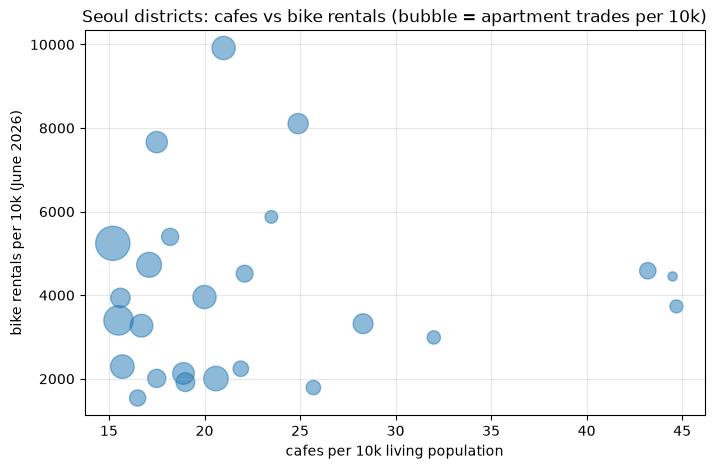

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(gu_rank["cafes_10k"], gu_rank["rentals_10k"], s=gu_rank["trades_10k"] * 40, alpha=.5)
ax.set_xlabel("cafes per 10k living population")
ax.set_ylabel("bike rentals per 10k (June 2026)")
ax.set_title("Seoul districts: cafes vs bike rentals (bubble = apartment trades per 10k)")
ax.grid(alpha=.3)
plt.show()

일부러 파일 경로로 바로 읽어 보세요. DuckDB 는 `read_parquet('s3://…')` 로 파일을 직접 열지만, Trino 는 반드시 카탈로그를 거쳐 **표 이름**으로 찾습니다(4주차 21장). 없는 표 이름도 마찬가지로 거절됩니다.

In [ ]:
for sql in ["SELECT count(*) FROM 's3://warehouse/t5/store'", "SELECT count(*) FROM stores"]:
    try:
        tq(sql)
    except TrinoUserError as e:
        print("질의 실패:", e.error_name, "—", e.message[:60])

질의 실패: SYNTAX_ERROR — line 1:22: mismatched input ''s3://warehouse/t5/store''. Exp
질의 실패: TABLE_NOT_FOUND — line 1:22: Table 'iceberg.t5.stores' does not exist


## 10단계 · Airflow DAG — 매월 올리기 → 정제 · 적재 → 대조 (오케스트레이션)

다음 달 파일이 오면 3~8단계를 다시 돌려야 합니다. 그 일을 함수 셋으로 묶어 `dags/t5_jobs.py` 에 두고, DAG 가 매월 차례로 부르게 합니다(8주차).
세 번째 함수 `check_keys` 가 이 프로젝트에서 가장 중요한 태스크입니다 — 새 달 자료에서 **대응표로도 못 잇는 행정동 코드**가 생기면 실패해서, 사람이 대응표를 고칠 때까지 멈춥니다.

In [ ]:
os.makedirs("dags", exist_ok=True)

In [ ]:
%%writefile dags/t5_jobs.py
"""T5 서울 생활 데이터 레이크하우스 — Airflow 가 매월 부르는 세 가지 일(노트북 3 · 4~8 · 9단계를 함수로 묶은 것)."""
import os

MINIO = os.environ.get("T5_MINIO", "localhost:9000")
REST = os.environ.get("T5_REST", "http://localhost:8181")
TRINO = os.environ.get("T5_TRINO", "localhost")
KNOWN_MISSING = {"11530800"}                     # 항동 — 2016년 코드를 쓰는 생활인구에 없는 동(6단계)


def upload_raw(files, ym, data_dir="data"):
    """① 수집 — 받은 파일을 raw/<출처>/ym=<달>/ 에 그대로 올리기."""
    from minio import Minio
    mc = Minio(MINIO, access_key="minioadmin", secret_key="minioadmin", secure=False)
    for f, src in files.items():
        mc.fput_object("raw", f"{src}/ym={ym}/{f}", os.path.join(data_dir, f))
    return len(files)


def load_tables(tables, catalog):
    """② 레이크 — Spark 표들을 Iceberg 로(overwrite 라 다시 돌려도 행이 늘지 않음). 표마다 행 수를 돌려줍니다."""
    import pyarrow as pa
    import pyarrow.parquet as pq
    out = {}
    for name, df in tables.items():
        df.coalesce(1).write.mode("overwrite").parquet(f"clean/{name}")
        t = pq.read_table(f"clean/{name}")
        t = t.cast(pa.schema([f.with_nullable(True) for f in t.schema]))
        ident = f"t5.{name}"
        if not catalog.table_exists(ident):
            catalog.create_table(ident, schema=t.schema)
        catalog.load_table(ident).overwrite(t)
        out[name] = t.num_rows
    return out


def check_keys():
    """③ 대조 — 생활인구와 동 차원표가 남김없이 이어지는지 Trino 로 확인. 모르는 코드가 있으면 실패."""
    import trino
    cur = trino.dbapi.connect(host=TRINO, port=8080, user="t5", catalog="iceberg", schema="t5").cursor()
    cur.execute("""SELECT DISTINCT p.dong_key FROM living_pop p
                   LEFT JOIN dong d ON d.dong_key = p.dong_key WHERE d.dong_key IS NULL""")
    pop_unmatched = {r[0] for r in cur.fetchall()}
    cur.execute("""SELECT d.dong_key FROM dong d
                   WHERE d.dong_key NOT IN (SELECT DISTINCT dong_key FROM living_pop)""")
    dong_unmatched = {r[0] for r in cur.fetchall()} - KNOWN_MISSING
    if pop_unmatched or dong_unmatched:
        raise ValueError(f"대응표에 없는 행정동 코드: 생활인구 {sorted(pop_unmatched)} · 상가 {sorted(dong_unmatched)}")
    return {"pop_unmatched": 0, "dong_unmatched": 0}

Writing dags/t5_jobs.py


In [ ]:
%%writefile dags/t5_lakehouse_monthly.py
from datetime import datetime, timedelta
from airflow import DAG
from airflow.operators.python import PythonOperator

with DAG(
    dag_id="t5_lakehouse_monthly",
    start_date=datetime(2026, 11, 1),
    schedule="0 6 15 * *",
    catchup=False,
    default_args={"owner": "t5", "retries": 1, "retry_delay": timedelta(minutes=30)},
    tags=["T5", "lakehouse"],
) as dag:
    def _upload(**ctx):
        import t5_jobs
        ym = ctx["data_interval_start"].strftime("%Y%m")
        return t5_jobs.upload_raw(ctx["params"].get("files", {}), ym)

    def _load(**_):
        raise NotImplementedError("Spark 정제(노트북 4~7단계)를 spark-submit 스크립트로 옮겨 붙이세요")

    def _check(**_):
        import t5_jobs
        return t5_jobs.check_keys()

    upload = PythonOperator(task_id="upload_raw", python_callable=_upload)
    load = PythonOperator(task_id="spark_clean_load", python_callable=_load)
    check = PythonOperator(task_id="check_keys", python_callable=_check)

    upload >> load >> check

Writing dags/t5_lakehouse_monthly.py


`spark_clean_load` 는 일부러 비워 두었습니다(오케스트레이션 담당의 첫 과제). 4~7단계의 Spark 코드를 `spark_clean.py` 로 옮겨 `SparkSubmitOperator` 로 부르거나, 4주차의 `spark-iceberg` 컨테이너에서 `spark-submit` 하는 `DockerOperator` 로 바꾸세요.

Airflow 가 할 일 가운데 둘(적재 · 대조)을 노트북에서 손으로 돌려 봅니다. 적재를 한 번 더 해도 행 수가 그대로이고(overwrite), 대조가 통과해야 합니다.

In [ ]:
sys.path.insert(0, os.path.abspath("dags"))
import t5_jobs
again = t5_jobs.load_tables(TABLES, cat)
print("다시 적재:", again)
print("대조:", t5_jobs.check_keys())

다시 적재: {'dong': 425, 'dong_crosswalk': 11, 'living_pop': 305280, 'store': 141126, 'bike_daily': 81909, 'apt_trade': 5374}


대조: {'pop_unmatched': 0, 'dong_unmatched': 0}


> **확인 포인트** — 다시 적재한 행 수가 8단계와 같고, 대조가 `{'pop_unmatched': 0, 'dong_unmatched': 0}` 로 통과합니다.

In [ ]:
assert again == ROWS and t5_jobs.check_keys() == {"pop_unmatched": 0, "dong_unmatched": 0}

일부러 대응표 없이 적재해 보세요 — 다음 달에 새 분동이 생겼는데 대응표를 고치지 않은 상황입니다. 대조 태스크가 실패해야 정상입니다. 확인한 뒤에는 원래대로 되돌립니다.

In [ ]:
t5_jobs.load_tables({"dong": store.groupBy(F.col("dong_cd").alias("dong_key"))
                     .agg(F.first("gu_cd").alias("gu_cd"), F.first("gu_nm").alias("gu_nm"), F.first("dong_nm").alias("dong_nm"))}, cat)
try:
    t5_jobs.check_keys()
except ValueError as e:
    print("대조 실패:", str(e)[:90])
t5_jobs.load_tables({"dong": dong}, cat)
print("되돌린 뒤:", t5_jobs.check_keys())

대조 실패: 대응표에 없는 행정동 코드: 생활인구 ['11230536', '11305590', '11305600', '11305606', '11305610', '1130562


되돌린 뒤: {'pop_unmatched': 0, 'dong_unmatched': 0}


진짜 검사는 Airflow 2.9.3 컨테이너 안에서 합니다(8주차와 같은 판). 메타 DB 를 만들고(`db migrate`), 읽기 오류 목록과 태스크 목록을 봅니다. 처음에는 이미지(약 2GB)를 받느라 몇 분 걸릴 수 있습니다.

In [ ]:
out = subprocess.run(
    ["docker", "compose", "-p", "t5", "--profile", "airflow", "run", "--rm", "airflow", "bash", "-c",
     "airflow db migrate > /dev/null 2>&1 && airflow dags list-import-errors && airflow tasks list t5_lakehouse_monthly"],
    capture_output=True, text=True)
print(out.stdout[-500:])


No data found
check_keys
spark_clean_load
upload_raw



> **확인 포인트** — 읽기 오류는 `No data found`, 태스크는 `check_keys · spark_clean_load · upload_raw` 셋이 찍힙니다.

In [ ]:
tasks = [t for t in out.stdout.split() if t in ("upload_raw", "spark_clean_load", "check_keys")]
assert out.returncode == 0 and "No data found" in out.stdout and len(tasks) == 3

## 11단계 · 정리와 더 해 보기 (오케스트레이션)

Spark 를 멈추고 컨테이너와 볼륨을 지웁니다. `down -v` 의 `-v` 가 MinIO · 카탈로그 볼륨까지 지웁니다 — 남겨 두고 싶으면 `-v` 를 빼세요.

In [ ]:
spark.stop()
conn.close()
!docker compose --progress quiet -p t5 --profile airflow down -v
left = subprocess.run(["docker", "ps", "-a", "-q", "--filter", "label=com.docker.compose.project=t5"], capture_output=True, text=True).stdout.split()
print("남은 컨테이너:", len(left))
assert left == []

남은 컨테이너: 0


> **확인 포인트** — `남은 컨테이너: 0`.

더 해 보기 — 역할별로 하나씩 골라 키우세요.

- 수집 · 스트리밍: 생활인구 7월분(행정동 단위 마지막 달)을 받아 `ym=202607/` 에 올리고, 같은 노트북을 달만 바꿔 돌려 보세요. 8월부터는 250m 격자 자료로 바뀌므로, 격자 → 행정동 대응을 어떻게 할지 직접 정해야 합니다.
- 레이크 · Spark: 6단계 「규칙」으로 이은 8줄을 행정안전부 행정동 변경 내역으로 확인해 근거 칸을 바꾸세요. 7단계는 행정동 경계(shp)로 바꿔 중심점 방식과 몇 곳이 달라지는지 세어 보세요.
- 조회 · 서비스: 9단계 질의를 Trino 의 뷰(`CREATE VIEW t5.dong_score AS …`)로 저장하고, 8주차처럼 Streamlit 화면에서 구를 고르면 동 순위가 나오게 하세요.
- 오케스트레이션: `spark_clean_load` 를 채우고, 일부러 대응표에서 한 줄을 지운 채 DAG 를 돌려 `check_keys` 가 재시도 1번 뒤 멈추는지 Airflow 화면에서 확인하세요.